# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Sulaiman Faiz Tsaqib | 5054251048 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **TensorFlow / Keras** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, tensorflow, dll).
# Set random seed dengan tf.keras.utils.set_random_seed(42).
# Cek apakah GPU tersedia dengan tf.config.list_physical_devices("GPU").
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

tf.keras.utils.set_random_seed(42)
print('GPU:', tf.config.list_physical_devices('GPU'))

GPU: []


In [2]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.
# Hanya fashion-mnist_test.csv yang tersedia, sehingga file ini dibagi menjadi data train (80%) dan test (20%)
df = pd.read_csv('fashion-mnist_test.csv')
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=42)
print('Train:', train_df.shape)
print('Test :', test_df.shape)

Train: (8000, 785)
Test : (2000, 785)


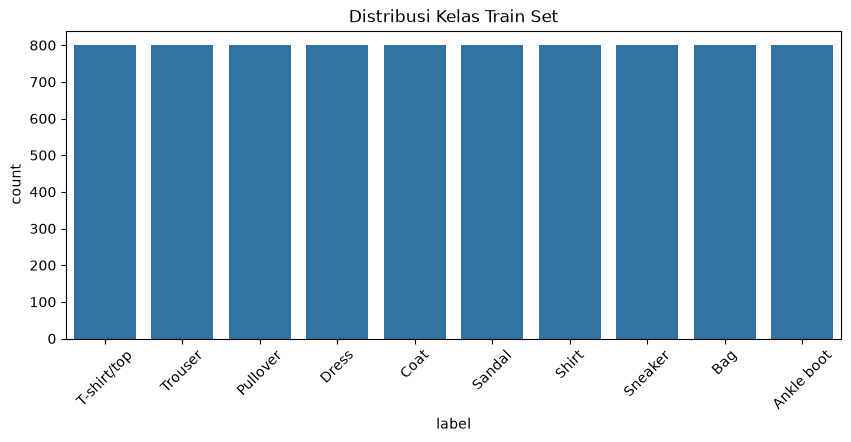

In [3]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.
classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

plt.figure(figsize=(10, 4))
sns.countplot(x=train_df['label'].map(dict(enumerate(classes))), order=classes)
plt.xticks(rotation=45)
plt.title('Distribusi Kelas Train Set')
plt.show()

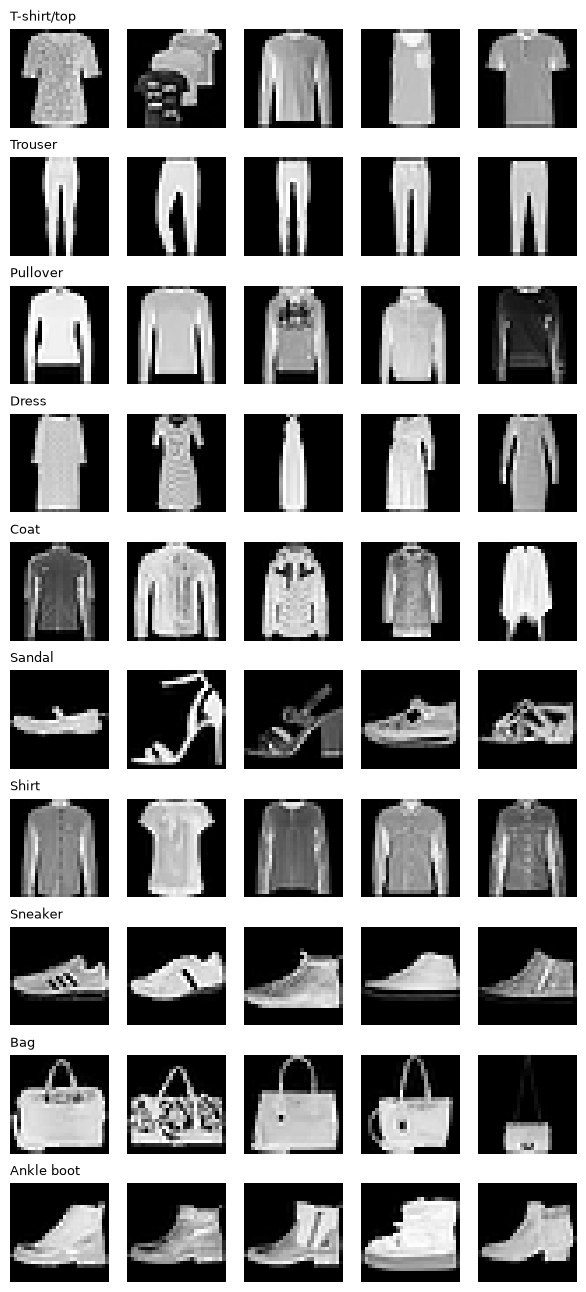

In [4]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?
fig, ax = plt.subplots(10, 5, figsize=(6, 13))
for i in range(10):
    imgs = train_df[train_df['label'] == i].iloc[:5, 1:].values
    for j in range(5):
        ax[i, j].imshow(imgs[j].reshape(28, 28), cmap='gray')
        ax[i, j].axis('off')
    ax[i, 0].set_title(classes[i], fontsize=9, loc='left')
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

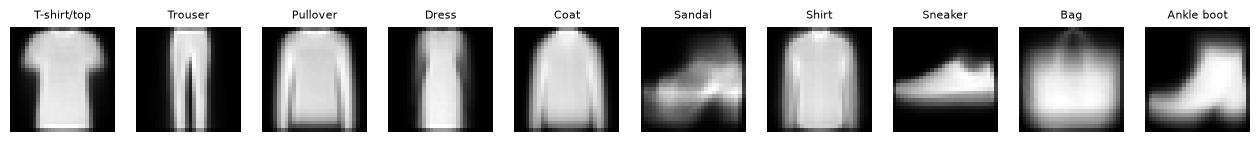

label
T-shirt/top    84.55
Trouser        57.79
Pullover       97.13
Dress          64.98
Coat           99.26
Sandal         35.87
Shirt          82.93
Sneaker        43.50
Bag            90.21
Ankle boot     75.54
dtype: float64


In [5]:
# Rata-rata gambar setiap kelas dan rata-rata intensitas piksel
fig, ax = plt.subplots(1, 10, figsize=(16, 2))
for i in range(10):
    ax[i].imshow(train_df[train_df['label'] == i].iloc[:, 1:].mean().values.reshape(28, 28), cmap='gray')
    ax[i].set_title(classes[i], fontsize=8)
    ax[i].axis('off')
plt.show()

print(train_df.iloc[:, 1:].mean(axis=1).groupby(train_df['label']).mean().rename(index=dict(enumerate(classes))).round(2))

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di TensorFlow/Keras, urutan dimensi gambar adalah **(batch, tinggi, lebar, channel)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)` |
| CNN | `(N, 28, 28, 1)` |

In [6]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.
X_train, y_train = train_df.drop(columns='label').values, train_df['label'].values
X_test, y_test = test_df.drop(columns='label').values, test_df['label'].values

In [7]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).
X_train = X_train / 255.0
X_test = X_test / 255.0

In [8]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, stratify=y_train, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

(7200, 784) (800, 784) (2000, 784)


In [9]:
# Ubah bentuk data sesuai kebutuhan model (lihat tabel di atas), pastikan bertipe float32.
# Contoh untuk CNN: X_train_cnn = X_train.reshape(-1, 28, 28, 1).astype("float32")
X_train, X_val, X_test = [a.astype('float32') for a in (X_train, X_val, X_test)]
X_train_cnn, X_val_cnn, X_test_cnn = [a.reshape(-1, 28, 28, 1) for a in (X_train, X_val, X_test)]
print(X_train.shape, X_train_cnn.shape)

(7200, 784) (7200, 28, 28, 1)


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output dengan aktivasi Softmax** dan **`sparse_categorical_crossentropy`** sebagai loss function (label berupa angka 0-9).

Contoh arsitektur: `Input(784) → Dense(256, ReLU) → Dense(128, ReLU) → Dense(10, Softmax)`

In [10]:
# Definisikan arsitektur ANN menggunakan keras.Sequential.
# Tampilkan ringkasan model beserta jumlah parameternya dengan model.summary().
ann = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])
ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Compile model dengan optimizer, loss="sparse_categorical_crossentropy", dan metrics=["accuracy"].
# Latih model dengan model.fit() menggunakan validation_data, simpan hasilnya ke variabel history.
def compile_fit(model, X_tr, X_va, epochs=15, batch_size=64, lr=1e-3):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model.fit(X_tr, y_train, validation_data=(X_va, y_val), epochs=epochs, batch_size=batch_size, verbose=2)

hist_ann = compile_fit(ann, X_train, X_val)

Epoch 1/15


113/113 - 1s - 9ms/step - accuracy: 0.7314 - loss: 0.7631 - val_accuracy: 0.7912 - val_loss: 0.6234


Epoch 2/15


113/113 - 0s - 3ms/step - accuracy: 0.8208 - loss: 0.5037 - val_accuracy: 0.8313 - val_loss: 0.5214


Epoch 3/15


113/113 - 0s - 2ms/step - accuracy: 0.8483 - loss: 0.4324 - val_accuracy: 0.8313 - val_loss: 0.5028


... (20 outputs left out)

Epoch 14/15


113/113 - 0s - 2ms/step - accuracy: 0.9244 - loss: 0.2022 - val_accuracy: 0.8438 - val_loss: 0.4906


Epoch 15/15


113/113 - 0s - 2ms/step - accuracy: 0.9269 - loss: 0.1949 - val_accuracy: 0.8500 - val_loss: 0.5130


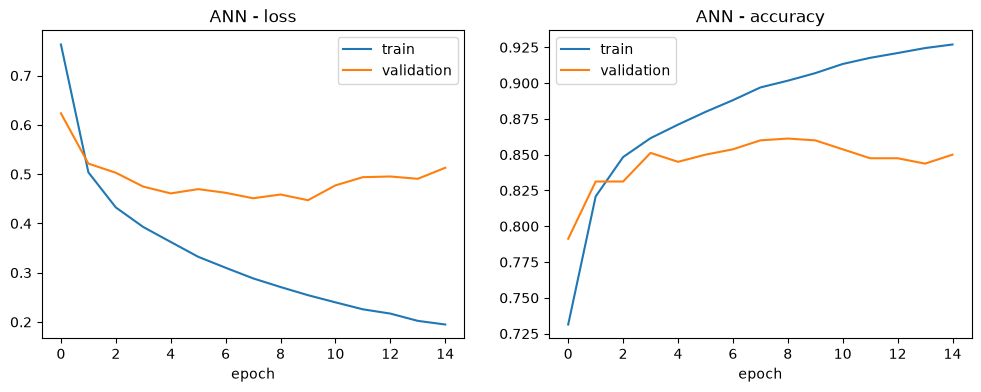

In [12]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.
def plot_history(history, title):
    h = history.history
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, m in zip(ax, ['loss', 'accuracy']):
        a.plot(h[m], label='train')
        a.plot(h['val_' + m], label='validation')
        a.set_title(f'{title} - {m}')
        a.set_xlabel('epoch')
        a.legend()
    plt.show()

plot_history(hist_ann, 'ANN')

In [13]:
# Lakukan prediksi pada test set. model.predict() menghasilkan probabilitas 10 kelas,
# ambil kelas dengan probabilitas terbesar menggunakan argmax(axis=1). Simpan hasil prediksi label.
y_pred_ann = ann.predict(X_test, verbose=0).argmax(axis=1)

## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2D (ReLU) → MaxPooling, lalu dilanjutkan Flatten dan Dense.

Contoh arsitektur: `[Conv2D(32, 3×3, ReLU) → MaxPooling2D(2×2)] → [Conv2D(64, 3×3, ReLU) → MaxPooling2D(2×2)] → Flatten → Dense(128, ReLU) → Dense(10, Softmax)`

In [14]:
# Definisikan arsitektur CNN sederhana menggunakan layers.Conv2D, layers.MaxPooling2D, layers.Flatten, dan layers.Dense.
# Gunakan keras.Input(shape=(28, 28, 1)) sebagai layer pertama.
# Tampilkan ringkasan model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1,
# lalu cocokkan dengan kolom "Output Shape" pada model.summary(). (padding="valid" berarti P = 0, padding="same" menjaga ukuran tetap)
# Perhitungan manual (W - K + 2P) / S + 1 dengan padding="valid" (P = 0):
# Conv2D 1     : (28 - 3) / 1 + 1 = 26 -> (26, 26, 32)
# MaxPooling 1 : (26 - 2) / 2 + 1 = 13 -> (13, 13, 32)
# Conv2D 2     : (13 - 3) / 1 + 1 = 11 -> (11, 11, 64)
# MaxPooling 2 : (11 - 2) / 2 + 1 = 5  -> (5, 5, 64)  (dibulatkan ke bawah)
# Flatten      : 5 x 5 x 64 = 1600
cnn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(2),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


113/113 - 2s - 14ms/step - accuracy: 0.6774 - loss: 0.9106 - val_accuracy: 0.7713 - val_loss: 0.6120


Epoch 2/15


113/113 - 1s - 7ms/step - accuracy: 0.8069 - loss: 0.5227 - val_accuracy: 0.8175 - val_loss: 0.4919


Epoch 3/15


113/113 - 1s - 7ms/step - accuracy: 0.8385 - loss: 0.4437 - val_accuracy: 0.8388 - val_loss: 0.4734


... (20 outputs left out)

Epoch 14/15


113/113 - 1s - 7ms/step - accuracy: 0.9343 - loss: 0.1833 - val_accuracy: 0.8788 - val_loss: 0.4245


Epoch 15/15


113/113 - 1s - 7ms/step - accuracy: 0.9360 - loss: 0.1741 - val_accuracy: 0.8850 - val_loss: 0.4431


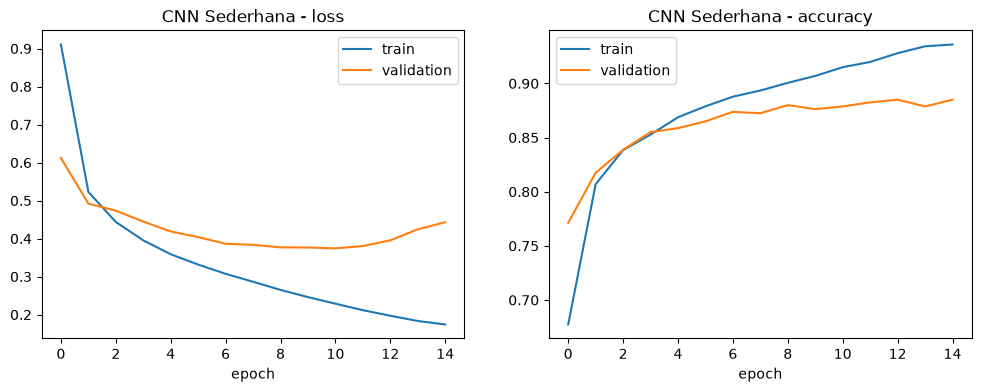

In [15]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.
hist_cnn = compile_fit(cnn, X_train_cnn, X_val_cnn)
plot_history(hist_cnn, 'CNN Sederhana')

In [16]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
y_pred_cnn = cnn.predict(X_test_cnn, verbose=0).argmax(axis=1)

## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [17]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: Conv2D (tanpa activation) -> layers.BatchNormalization() -> layers.Activation("relu") -> MaxPooling2D.
# Tambahkan layers.Dropout(rate) sebelum layer output.
# Tampilkan ringkasan model beserta jumlah parameternya.
cnn_bn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(2),
    layers.Conv2D(64, 3),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])
cnn_bn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,418 (880.54 KB)

 Trainable params: 225,226 (879.79 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/15


113/113 - 2s - 21ms/step - accuracy: 0.6642 - loss: 0.9684 - val_accuracy: 0.3638 - val_loss: 1.8604


Epoch 2/15


113/113 - 1s - 11ms/step - accuracy: 0.7732 - loss: 0.6217 - val_accuracy: 0.5587 - val_loss: 1.3792


Epoch 3/15


113/113 - 2s - 13ms/step - accuracy: 0.8057 - loss: 0.5326 - val_accuracy: 0.7188 - val_loss: 0.7803


... (20 outputs left out)

Epoch 14/15


113/113 - 1s - 12ms/step - accuracy: 0.9007 - loss: 0.2636 - val_accuracy: 0.8687 - val_loss: 0.3945


Epoch 15/15


113/113 - 1s - 11ms/step - accuracy: 0.9094 - loss: 0.2398 - val_accuracy: 0.8650 - val_loss: 0.4100


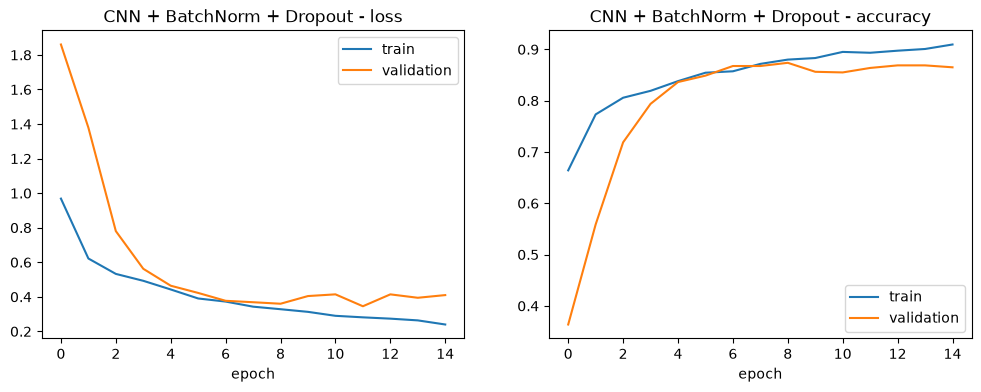

In [18]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.
hist_cnn_bn = compile_fit(cnn_bn, X_train_cnn, X_val_cnn)
plot_history(hist_cnn_bn, 'CNN + BatchNorm + Dropout')

In [19]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
y_pred_cnn_bn = cnn_bn.predict(X_test_cnn, verbose=0).argmax(axis=1)

# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.
models = {'ANN': (ann, y_pred_ann), 'CNN Sederhana': (cnn, y_pred_cnn), 'CNN + BN + Dropout': (cnn_bn, y_pred_cnn_bn)}
results = pd.DataFrame({
    name: {
        'Accuracy': accuracy_score(y_test, p),
        'Precision': precision_score(y_test, p, average='macro'),
        'Recall': recall_score(y_test, p, average='macro'),
        'F1-Score': f1_score(y_test, p, average='macro'),
        'Parameter': m.count_params(),
    } for name, (m, p) in models.items()
}).T
best_name = results['Accuracy'].idxmax()
best_model, best_pred = models[best_name]
print('Model terbaik:', best_name)
results

Model terbaik: CNN Sederhana


,Accuracy,Precision,Recall,F1-Score,Parameter
ANN,0.8340,0.847615,0.8340,0.830834,235146.0
CNN Sederhana,0.8445,0.868648,0.8445,0.843218,225034.0
CNN + BN + Dropout,0.8420,0.870473,0.8420,0.841630,225418.0


In [21]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.
print(classification_report(y_test, best_pred, target_names=classes, digits=4))

              precision    recall  f1-score   support

 T-shirt/top     0.8919    0.6600    0.7586       200
     Trouser     0.9948    0.9600    0.9771       200
    Pullover     0.9394    0.4650    0.6221       200
       Dress     0.8714    0.9150    0.8927       200
        Coat     0.6498    0.9000    0.7547       200
      Sandal     0.9947    0.9350    0.9639       200
       Shirt     0.5485    0.7350    0.6282       200
     Sneaker     0.9216    0.9400    0.9307       200
         Bag     0.9561    0.9800    0.9679       200
  Ankle boot     0.9183    0.9550    0.9363       200

    accuracy                         0.8445      2000
   macro avg     0.8686    0.8445    0.8432      2000
weighted avg     0.8686    0.8445    0.8432      2000



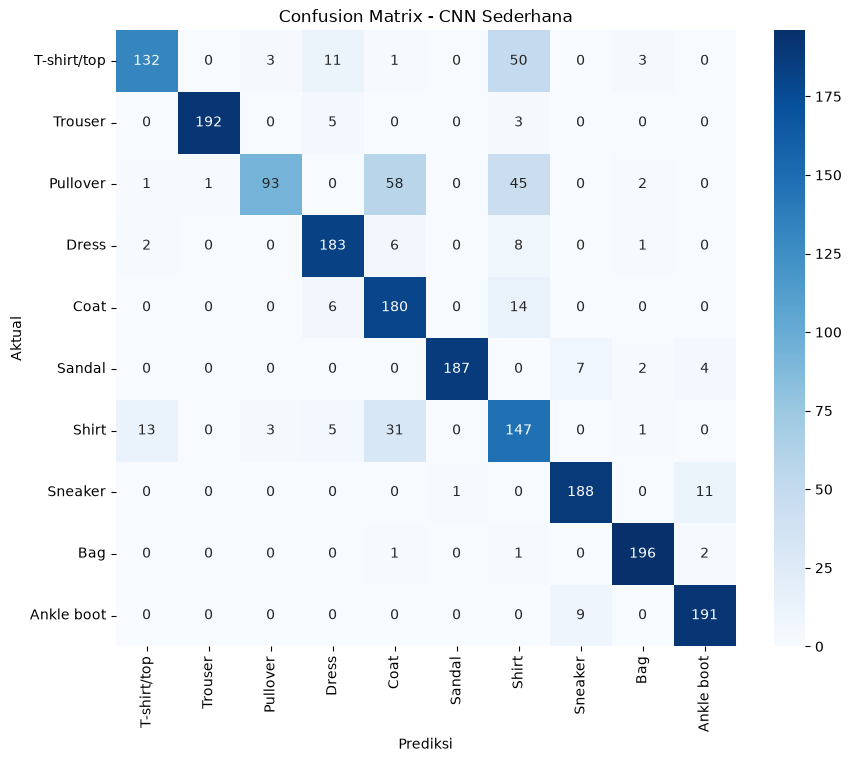

In [22]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, best_pred), annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title(f'Confusion Matrix - {best_name}')
plt.show()

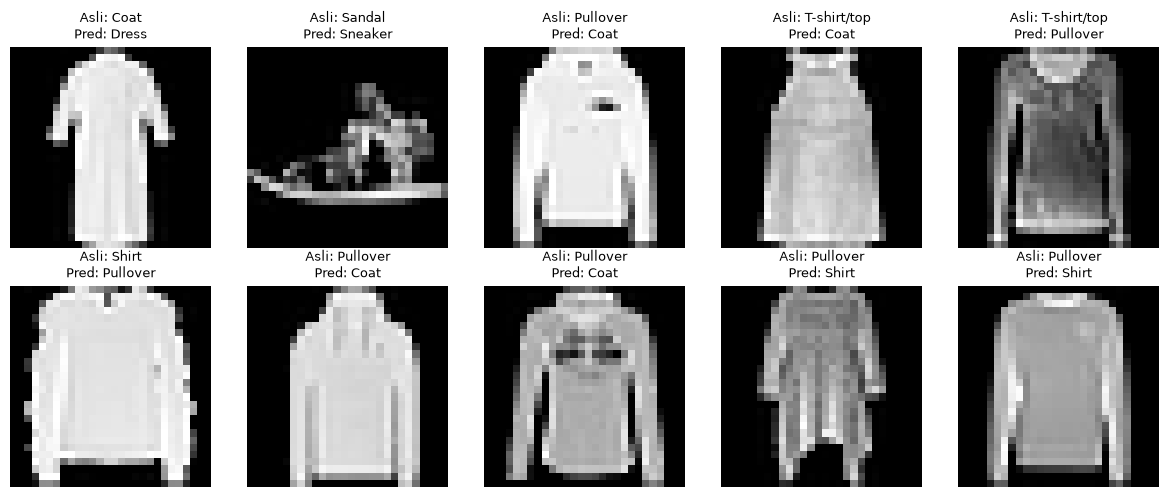

In [23]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.
wrong = np.where(best_pred != y_test)[0][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for a, i in zip(ax.ravel(), wrong):
    a.imshow(X_test[i].reshape(28, 28), cmap='gray')
    a.set_title(f'Asli: {classes[y_test[i]]}\nPred: {classes[best_pred[i]]}', fontsize=9)
    a.axis('off')
plt.tight_layout()
plt.show()

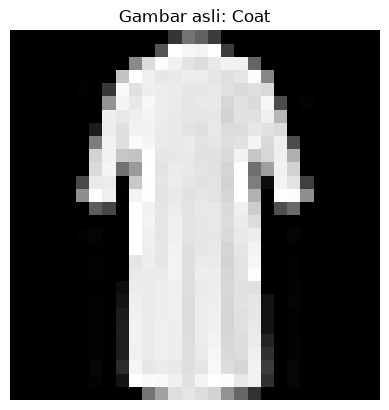

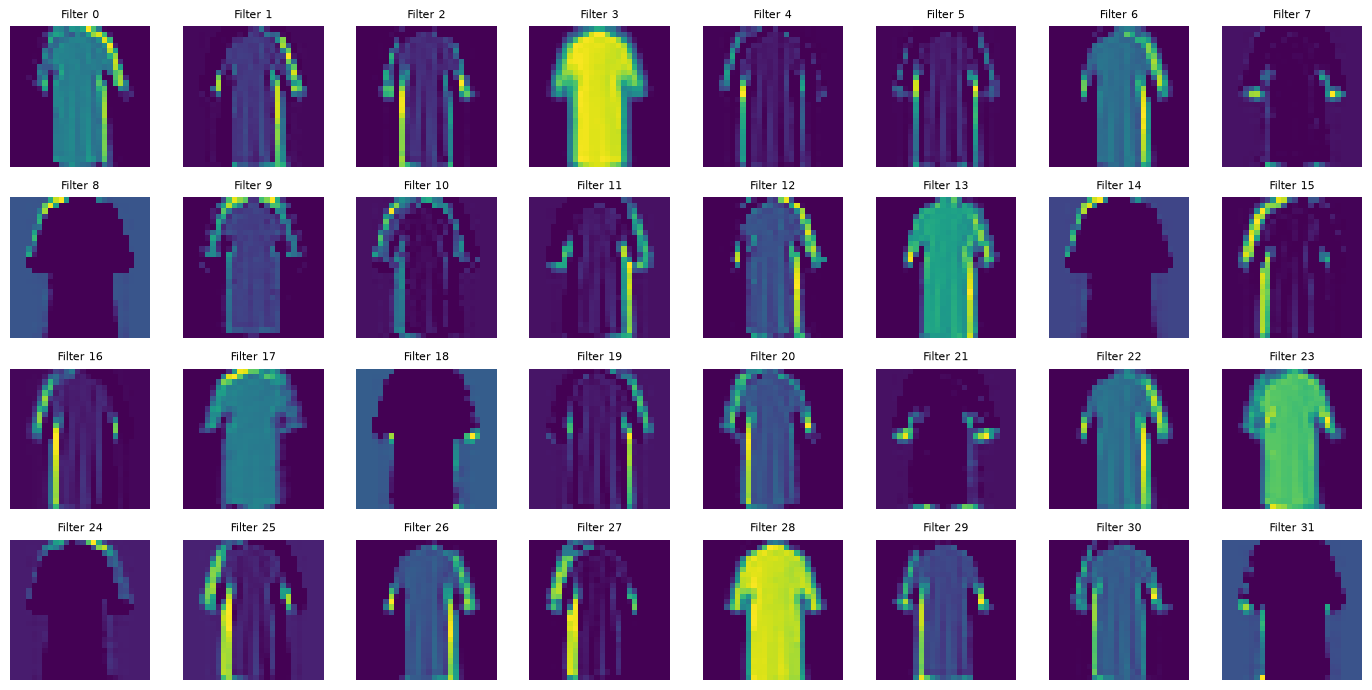

In [24]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Buat model baru yang output-nya adalah output layer konvolusi pertama:
#   feature_model = keras.Model(inputs=model.inputs, outputs=model.layers[0].output)
# lalu tampilkan setiap channel hasil feature_model.predict() sebagai gambar.
# Apa saja pola yang ditangkap oleh masing-masing filter?
feature_model = keras.Model(inputs=best_model.inputs, outputs=best_model.layers[0].output)
fmap = feature_model.predict(X_test_cnn[:1], verbose=0)[0]

plt.imshow(X_test[0].reshape(28, 28), cmap='gray')
plt.title(f'Gambar asli: {classes[y_test[0]]}')
plt.axis('off')
plt.show()

fig, ax = plt.subplots(4, 8, figsize=(14, 7))
for i, a in enumerate(ax.ravel()):
    a.imshow(fmap[:, :, i], cmap='viridis')
    a.set_title(f'Filter {i}', fontsize=8)
    a.axis('off')
plt.tight_layout()
plt.show()

In [25]:
# Simpan model terbaik dengan model.save("model.keras").
# Model ini akan digunakan kembali pada tugas Deployment.
best_model.save('model.keras')
print('Model disimpan:', best_name)

Model disimpan: CNN Sederhana


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout berdasarkan hasil evaluasi. Kaitkan perbedaan performa dengan jumlah parameter dan cara masing-masing model memproses gambar. Bahas pula pengaruh Batch Normalization dan Dropout terhadap learning curve, serta kelas-kelas yang sulit dibedakan oleh model. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

**Catatan data:** hanya file `fashion-mnist_test.csv` (10.000 gambar) yang tersedia, sehingga data dibagi menjadi 7.200 train, 800 validation, dan 2.000 test (stratified, setiap kelas seimbang). Ketiga model dilatih dengan pengaturan yang sama: Adam (lr = 0.001), batch size 64, dan 15 epoch.

**Hasil evaluasi pada test set (macro average):**

| Model | Accuracy | Precision | Recall | F1-Score | Parameter |
|---|---|---|---|---|---|
| ANN | 0.8340 | 0.8476 | 0.8340 | 0.8308 | 235.146 |
| CNN Sederhana | **0.8445** | 0.8686 | **0.8445** | **0.8432** | 225.034 |
| CNN + BN + Dropout | 0.8420 | **0.8705** | 0.8420 | 0.8416 | 225.418 |

1. **ANN vs CNN.** Kedua CNN mengungguli ANN (accuracy +0.8–1.1 poin, precision +2.1–2.3 poin), padahal parameternya justru lebih sedikit. ANN mem-flatten gambar menjadi 784 nilai sehingga informasi letak piksel yang bertetangga hilang. CNN memakai filter 3×3 yang sama (weight sharing) di seluruh gambar untuk mendeteksi pola lokal seperti tepi, bahu, dan lengan. MaxPooling membuat pola tersebut tetap terdeteksi walaupun posisinya sedikit bergeser.

2. **Kaitan dengan jumlah parameter.** Dengan `padding="valid"`, output konvolusi terakhir berukuran 5×5×64 = 1.600, sehingga CNN hanya memiliki 225.034 parameter, lebih sedikit dari ANN (235.146). Bagian konvolusinya sendiri hanya 18.816 parameter, dan sebagian besar parameter (204.928) ada di `Dense(128)` setelah Flatten. Artinya keunggulan CNN berasal dari cara memproses gambar, bukan dari jumlah parameter. BatchNormalization menambah 384 parameter: 192 trainable (gamma, beta) dan 192 non-trainable (moving mean dan variance).

3. **Learning curve dan pengaruh Batch Normalization serta Dropout.**
   - **ANN** paling cepat overfitting. Val loss terendah 0.4471 pada epoch 10, lalu naik ke 0.5130, sementara train loss terus turun. Selisih accuracy train dan validation di akhir training sekitar 7.7% (0.927 vs 0.850).
   - **CNN sederhana** juga overfitting. Val loss terendah 0.3744 pada epoch 11, lalu naik ke 0.4431. Selisih accuracy di akhir training sekitar 5.1% (0.936 vs 0.885).
   - **CNN + BN + Dropout** memiliki selisih train dan validation terkecil (0.909 vs 0.865, sekitar 4.4%) dan val loss terendah dari semua model (0.3454). Dropout 0.5 menahan model dari menghafal data train, sehingga train accuracy-nya lebih rendah dari CNN sederhana. Pada epoch awal, val accuracy-nya sangat rendah (0.36 pada epoch 1). Penyebabnya, saat evaluasi BatchNormalization memakai *moving mean/variance* yang di Keras diperbarui perlahan (momentum 0.99), sehingga statistiknya belum sesuai dengan data. Setelah epoch 5, kurvanya sudah menyusul.
   - Accuracy test CNN + BN + Dropout (0.8420) sedikit di bawah CNN sederhana (0.8445). Selisihnya hanya 5 gambar dari 2.000, sehingga keduanya praktis setara. Model yang dievaluasi adalah bobot epoch terakhir, sementara val accuracy masih naik-turun antar epoch. Accuracy test semua model juga lebih rendah dari val accuracy-nya (sekitar 0.84 vs 0.85–0.88), karena validation set hanya 800 gambar sehingga estimasinya lebih bervariasi.

4. **Kelas yang sulit dibedakan.** Berdasarkan classification report model terbaik (CNN sederhana), kelas dengan F1 terendah adalah **Pullover** (0.6221, recall hanya 0.465), **Shirt** (0.6282), **Coat** (0.7547), dan **T-shirt/top** (0.7586). Pasangan yang paling sering tertukar pada confusion matrix:
   - Pullover → Coat (58 gambar) dan Pullover → Shirt (45)
   - T-shirt/top → Shirt (50) dan Shirt → T-shirt/top (13)
   - Shirt → Coat (31) dan Coat → Shirt (14)
   - Sneaker → Ankle boot (11) dan T-shirt/top → Dress (11)

   Pakaian atas memiliki siluet yang hampir sama pada resolusi 28×28 grayscale. Pembedanya hanya detail kecil seperti kancing, kerah, resleting, atau panjang lengan. Contoh gambar yang salah klasifikasi memperlihatkan hal ini, misalnya pullover polos yang terlihat seperti coat. Sebaliknya, Trouser, Bag, dan Sandal memiliki bentuk yang khas sehingga F1-nya di atas 0.96.

5. **Feature map.** Filter pada layer konvolusi pertama sudah mempelajari pola dasar. Filter 3, 23, dan 28 aktif di seluruh badan pakaian sehingga berfungsi seperti detektor siluet. Filter 8, 14, 18, dan 31 justru aktif di latar belakang, kebalikan dari siluet. Filter 1, 11, 13, dan 16 menyorot tepi vertikal sisi pakaian, sedangkan filter 9, 15, 17, dan 24 menyorot tepi atas seperti bahu dan kerah. Filter 7 dan 21 menyorot ujung lengan. Pola-pola sederhana ini kemudian digabungkan oleh layer berikutnya menjadi fitur yang lebih kompleks.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

1. CNN lebih cocok untuk klasifikasi gambar dibanding ANN biasa. Dengan parameter lebih sedikit, CNN sederhana mencapai accuracy 0.8445 dan F1 macro 0.8432, dibanding ANN dengan accuracy 0.8340 dan F1 0.8308.
2. CNN sederhana dan CNN + BN + Dropout memiliki performa test yang setara (selisih 0.25 poin). CNN sederhana sedikit unggul di accuracy, sehingga disimpan sebagai model terbaik (`model.keras`). BatchNorm dan Dropout terbukti mengurangi overfitting: selisih train dan validation paling kecil dan val loss paling rendah.
3. Kesalahan terbesar terjadi pada kelas pakaian atas yang mirip secara visual (Pullover, Shirt, Coat, T-shirt/top).
4. Semua model menunjukkan overfitting setelah sekitar epoch 10, karena data latih hanya 7.200 gambar.

**Saran:**
- Menggunakan data train lengkap Fashion-MNIST (60.000 gambar).
- Menambahkan `EarlyStopping(monitor="val_loss", restore_best_weights=True)` agar bobot yang dipakai adalah bobot terbaik, bukan bobot epoch terakhir.
- Menambahkan data augmentation (`RandomTranslation`, `RandomFlip`) dan Dropout di antara blok konvolusi untuk mengurangi overfitting.
- Mencoba arsitektur yang lebih dalam dengan `padding="same"` serta learning rate scheduler, dan melatih model dengan BatchNorm lebih lama karena kurvanya masih membaik.